# Решающие деревья и случайный лес

Теорию (энтропия, Джини, бэггинг, случайный лес) вы уже видели на лекции, поэтому здесь в основном код. Ноутбук рассчитан примерно на 30 минут.

**План**

1. Дерево на `if / elif / else` своими руками
2. Дерево в `sklearn`: все основные методы на одном примере
3. Переобучение и гиперпараметры
4. Регрессия
5. Случайный лес
6. Бустинг, LightGBM, CatBoost (кратко)

В ноутбуке 5 заданий. В каждом есть ячейка с проверкой: она сразу показывает, получилось или нет. Места, где нужно писать код, помечены словом `TODO`.

In [3]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris, load_breast_cancer, make_moons
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
plt.rcParams["figure.dpi"] = 110


def check(condition, ok, fail):
    print(("Верно: " + ok) if condition else ("Пока нет: " + fail))


def run_check(fn):
    # запускает проверку и не падает, если задание ещё не заполнено
    try:
        fn()
    except (NameError, TypeError, AttributeError) as e:
        print(f"Пока нет: задание не заполнено ({type(e).__name__}: {e})")

## 1. Дерево руками

Работаем с классическим датасетом Iris (ирисы, 150 цветов, 3 вида). Он встроен в `sklearn`. По размерам цветка нужно определить его вид: `setosa`, `versicolor` или `virginica`.

,sepal_length,sepal_width,petal_length,petal_width,target,species
73,6.1,2.8,4.7,1.2,1,versicolor
18,5.7,3.8,1.7,0.3,0,setosa
118,7.7,2.6,6.9,2.3,2,virginica
78,6.0,2.9,4.5,1.5,1,versicolor
76,6.8,2.8,4.8,1.4,1,versicolor


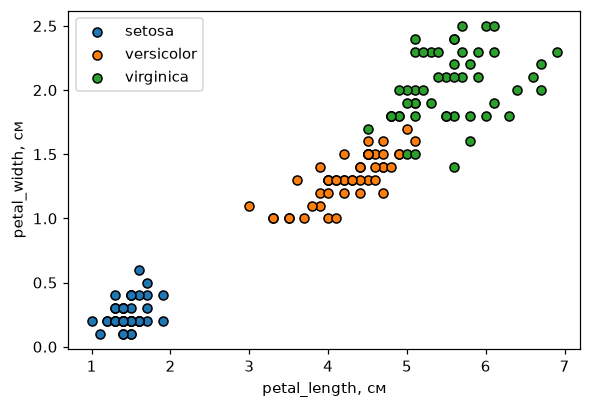

In [4]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()
feature_names = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
df.columns = feature_names + ["target"]
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))
display(df.sample(5, random_state=RANDOM_STATE))

colors = {"setosa": "tab:blue", "versicolor": "tab:orange", "virginica": "tab:green"}
fig, ax = plt.subplots(figsize=(6, 4))
for name, part in df.groupby("species"):
    ax.scatter(part["petal_length"], part["petal_width"], label=name, c=colors[name], edgecolor="k", s=35)
ax.set_xlabel("petal_length, см")
ax.set_ylabel("petal_width, см")
ax.legend()
plt.show()

Дерево решений — это вложенные `if`. Напомним, как части дерева выглядят в коде:

| Часть дерева | Что это | В коде |
|---|---|---|
| **Узел** (node) | вопрос про признак: «длина лепестка меньше 2.5?» | условие в `if` / `elif` |
| **Корневой узел** | самый первый вопрос | первый `if` |
| **Ветвь** (branch) | ответ на вопрос, «да» или «нет» | ветка `if` / `else` |
| **Лист** (leaf) | итоговое решение, вопросов больше нет | `return "класс"` |

Глубина дерева — число вопросов в самом длинном пути от корня до листа. Наше дерево будет глубины 2.

```
          [ petal_length < ??? ]                 <- корневой узел
             да /          \ нет                 <- ветви
               /            \
         setosa       [ petal_width < ??? ]       <- внутренний узел
         (лист)          да /        \ нет
                           /          \
                   versicolor        virginica    <- листья
```

Пороги можно найти в таблице: минимум и максимум признаков по каждому виду.

In [5]:
df.groupby("species")[["petal_length", "petal_width"]].agg(["min", "max"])

petal_length      petal_width     
                    min  max         min  max
species                                      
setosa              1.0  1.9         0.1  0.6
versicolor          3.0  5.1         1.0  1.8
virginica           4.5  6.9         1.4  2.5

### Задание 1. Дерево на `if / elif / else`

Замените два `TODO` числами так, чтобы accuracy была не ниже 0.9. У `versicolor` и `virginica` ширина лепестка немного пересекается, поэтому идеального порога нет: берите разумный.

In [6]:
def my_tree(petal_length, petal_width):
    if petal_length < 2.0:        # корневой узел: отделяем setosa от остальных
        return "setosa"            # лист
    elif petal_width < 1.8:       # внутренний узел: versicolor или virginica?
        return "versicolor"        # лист
    else:
        return "virginica"         # лист


def _check():
    preds = np.array([my_tree(l, w) for l, w in zip(df["petal_length"], df["petal_width"])])
    acc = (preds == df["species"].values).mean()
    check(acc >= 0.9, f"accuracy = {acc:.3f}", f"accuracy = {acc:.3f}, нужно хотя бы 0.9; посмотрите на таблицу выше")

run_check(_check)

Верно: accuracy = 0.960


## 2. Дерево в `sklearn`

Пороги мы подбирали глазами. `sklearn` делает это сам: перебирает признаки и пороги и берёт вопрос, который лучше всего «очищает» данные (по Джини или энтропии, как на лекции).

Ниже один пример со всеми основными методами. **Эти методы одинаковы у любой модели `sklearn`** (деревья, леса, линейные модели, kNN и так далее), различаются только аргументы при создании модели.

In [7]:
X = df[feature_names]
y = df["target"]                       # классы закодированы числами 0, 1, 2

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE)

model = DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE)   # создать модель
model.fit(X_train, y_train)                                              # обучить

print("predict:        ", model.predict(X_test[:5]))                     # предсказанные классы
print("predict_proba:\n", model.predict_proba(X_test[:5]).round(2))      # вероятности классов
print("score:          ", round(model.score(X_test, y_test), 3))         # accuracy на тесте
print("feature_importances_:", {k: round(float(v), 2) for k, v in zip(feature_names, model.feature_importances_)})
print("get_params:     ", model.get_params())                            # все гиперпараметры модели

predict:         [2 1 1 2 2]
predict_proba:
 [[0.   0.06 0.94]
 [0.   0.97 0.03]
 [0.   0.97 0.03]
 [0.   0.06 0.94]
 [0.   0.06 0.94]]
score:           0.889
feature_importances_: {'sepal_length': 0.0, 'sepal_width': 0.0, 'petal_length': 0.54, 'petal_width': 0.46}
get_params:      {'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': 2, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 42, 'splitter': 'best'}


Что за аргументы мы использовали:

| Аргумент | Что делает |
|---|---|
| `test_size=0.3` | какая доля данных откладывается на проверку; модель её никогда не видит при обучении |
| `stratify=y` | сохраняет доли классов и в обучении, и в тесте. Без этого на маленькой выборке в тест может случайно попасть слишком мало объектов одного из классов |
| `random_state` | фиксирует случайность: при одном и том же числе результат одинаков при каждом запуске. Само число неважно, важно что оно одно и то же |
| `max_depth=2` | максимальная глубина дерева (подробнее в части 3) |

Дерево можно нарисовать. В каждом прямоугольнике: вопрос (если это узел), `gini` (насколько перемешаны классы), `samples` (сколько объектов сюда дошло), `value` (сколько из них каждого класса), `class` (какой класс победил). У листьев вопроса нет.

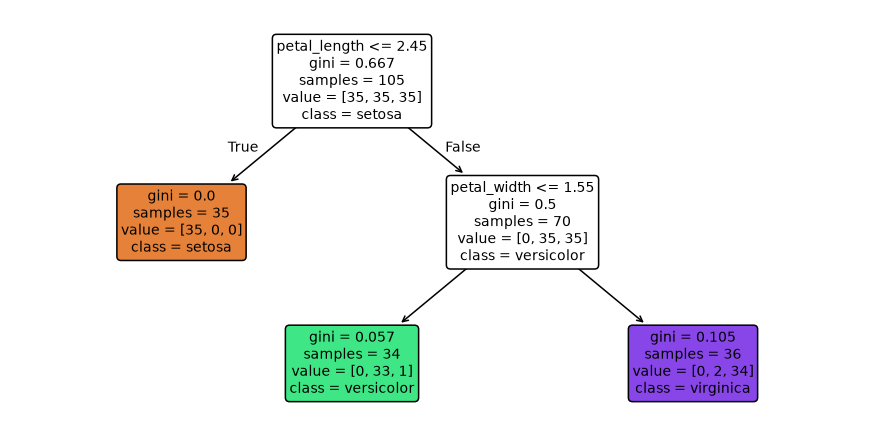

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
plot_tree(model, feature_names=feature_names, class_names=list(iris.target_names),
          filled=True, rounded=True, fontsize=9, ax=ax)
plt.show()

### Задание 2. Индекс Джини

Напишите функцию `gini(counts)`, где `counts` — число объектов каждого класса в узле, например `[35, 35, 35]`. Формула: $1 - \sum p_i^2$, где $p_i$ — доля класса $i$.

In [9]:
def gini(counts):
    p = np.array(counts) / np.sum(counts)      # доли классов
    return 1 - sum(p**2)                                # 1 - сумма квадратов долей


def _check():
    ok = abs(gini([50, 50]) - 0.5) < 1e-9 and abs(gini([10, 0, 0])) < 1e-9 and abs(gini([30, 30, 30]) - 2 / 3) < 1e-9
    check(ok, "функция работает", "проверьте формулу: gini([50, 50]) должно быть 0.5, gini([10, 0, 0]) должно быть 0")
    if ok:
        print("Джини корня (ваша функция):", round(gini(np.bincount(y_train)), 3),
              "| в дереве выше:", round(model.tree_.impurity[0], 3))

run_check(_check)

Верно: функция работает
Джини корня (ваша функция): 0.667 | в дереве выше: 0.667


## 3. Переобучение и гиперпараметры

Дерево без ограничений делит данные, пока в каждом листе не останется один объект: обучение оно выучит идеально, но на новых данных будет ошибаться. Аналогия: если учить дерево определять тип аниме-героини (цундере, кудере и так далее) по нескольким десяткам примеров, оно может вывести правило «розовые волосы, значит цундере» только потому, что так совпало у трёх героинь из выборки. На обучении ошибок ноль, а на новых героинях сплошные промахи. Чтобы увидеть это на цифрах, возьмём шумные данные «две луны» (`make_moons`) и будем увеличивать `max_depth`.

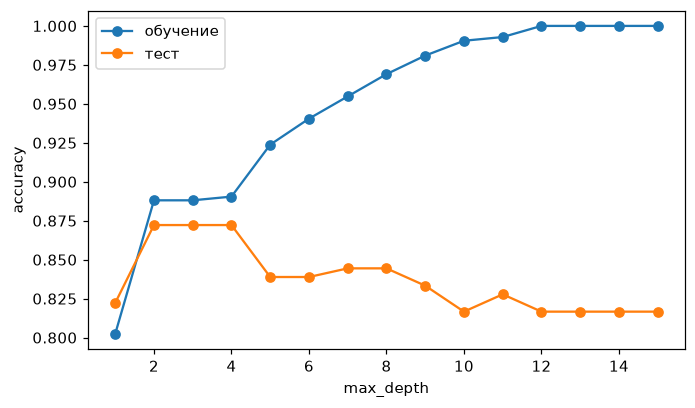

Лучшая глубина на тесте: 2


In [10]:
X_moon, y_moon = make_moons(n_samples=600, noise=0.35, random_state=RANDOM_STATE)
Xm_train, Xm_test, ym_train, ym_test = train_test_split(
    X_moon, y_moon, test_size=0.3, stratify=y_moon, random_state=RANDOM_STATE)

depths = range(1, 16)
train_acc, test_acc = [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE).fit(Xm_train, ym_train)
    train_acc.append(m.score(Xm_train, ym_train))
    test_acc.append(m.score(Xm_test, ym_test))

plt.figure(figsize=(7, 4))
plt.plot(depths, train_acc, "o-", label="обучение")
plt.plot(depths, test_acc, "o-", label="тест")
plt.xlabel("max_depth")
plt.ylabel("accuracy")
plt.legend()
plt.show()
print("Лучшая глубина на тесте:", depths[int(np.argmax(test_acc))])

Обучение растёт до 100%, а тест на какой-то глубине перестаёт расти и начинает падать. Разрыв между кривыми и есть переобучение.

Главные аргументы, которыми дерево ограничивают:

| Аргумент | Что делает |
|---|---|
| `max_depth` | максимальная глубина дерева |
| `min_samples_leaf` | минимум объектов в листе. Не даёт делать листья из одного-двух объектов, то есть запоминать выбросы |
| `criterion` | `"gini"` (по умолчанию) или `"entropy"`. На практике почти не влияет на качество |
| `max_features` | сколько признаков случайно рассматривается при выборе вопроса **в каждом узле** (по умолчанию все). Пригодится в случайном лесу |

### Задание 3. Победить переобучение

Сейчас дерево без ограничений. Измените аргументы в `DecisionTreeClassifier(...)` так, чтобы accuracy на тесте была **не ниже 0.86**. Можно использовать `max_depth`, `min_samples_leaf` или оба.

In [11]:



tree_moon = DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)      # TODO: добавьте ограничения
tree_moon.fit(Xm_train, ym_train)


def _check():
    tr, te = tree_moon.score(Xm_train, ym_train), tree_moon.score(Xm_test, ym_test)
    print(f"train = {tr:.3f}, test = {te:.3f}, листьев: {tree_moon.get_n_leaves()}")
    check(te >= 0.86, "переобучение побеждено", "нужно test >= 0.86, добавьте ограничения")

run_check(_check)

train = 0.890, test = 0.872, листьев: 12
Верно: переобучение побеждено


## 4. Дерево-регрессор

Если предсказываем число, а не класс, берут `DecisionTreeRegressor`. Отличия от лекции в двух словах: лист выдаёт **среднее** значение таргета объектов в нём, а вопросы выбираются по MSE. Методы те же: `fit`, `predict`, `score` (только `score` теперь возвращает $R^2$, а не accuracy).

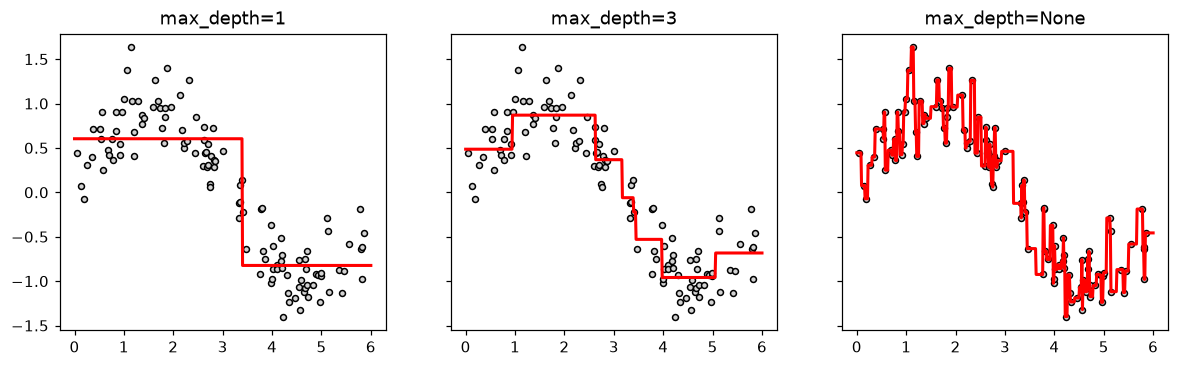

In [12]:
rng = np.random.default_rng(RANDOM_STATE)
X_reg = np.sort(rng.uniform(0, 6, 120)).reshape(-1, 1)
y_reg = np.sin(X_reg).ravel() + rng.normal(0, 0.25, 120)       # синус и шум
x_grid = np.linspace(0, 6, 500).reshape(-1, 1)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, d in zip(axes, [1, 3, None]):
    reg = DecisionTreeRegressor(max_depth=d, random_state=RANDOM_STATE).fit(X_reg, y_reg)
    ax.scatter(X_reg, y_reg, c="lightgray", edgecolor="k", s=15)
    ax.plot(x_grid, reg.predict(x_grid), "r", lw=2)
    ax.set_title(f"max_depth={d}")
plt.show()

Предсказание дерева — ступеньки (в каждом листе константа). Без ограничений дерево проходит через каждую точку, включая шум. Тот же эффект переобучения, что и в классификации.

## 5. Случайный лес

Одно дерево сильно зависит от случайностей в данных: чуть другая выборка даёт заметно другое дерево. Лес усредняет много деревьев.

Представьте, что тип героини определяет не один зритель, а сто. Каждый видел только часть тайтлов (это и есть бутстрап-выборка), и каждый обращает внимание на что-то своё: один на реплики, другой на причёску, третий на поведение в напряжённых сценах (это случайные признаки). Ошибки отдельных зрителей друг друга гасят, и общий вердикт получается стабильнее, чем мнение любого из них. Случайный лес устроен точно так же.

В лесу каждое дерево обучается на **бутстрап-выборке**: из `n` объектов выбирается `n` объектов **с возвращением**, поэтому часть объектов повторяется, а часть (около 37%) не попадает в выборку вообще.

Работаем с датасетом `breast cancer` (569 пациентов, 30 признаков, нужно отличить доброкачественную опухоль от злокачественной).

In [13]:
bc = load_breast_cancer()
Xb, yb = bc.data, bc.target
Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    Xb, yb, test_size=0.3, stratify=yb, random_state=RANDOM_STATE)

single_tree = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(Xb_train, yb_train)
print(f"Одно дерево без ограничений: accuracy на тесте = {single_tree.score(Xb_test, yb_test):.3f}")

Одно дерево без ограничений: accuracy на тесте = 0.918


### Задание 4. Бэггинг руками

Допишите два места:

1. `idx` — индексы бутстрап-выборки (`n` номеров **с возвращением**; подойдёт `rng.integers(0, n, size=n)`);
2. `bagging_pred` — предсказание ансамбля. Для двух классов 0/1: берём среднее голосов деревьев по каждому объекту и считаем ответом 1, если оно не меньше 0.5.

Цель: ансамбль из 50 деревьев должен дать accuracy не ниже 0.93.

In [14]:
rng = np.random.default_rng(RANDOM_STATE)
n = len(Xb_train)

trees = []
for i in range(50):
    idx = rng.integers(0, n, size=n)                                # индексы бутстрап-выборки
    tree = DecisionTreeClassifier(random_state=i).fit(Xb_train[idx], yb_train[idx])
    trees.append(tree)

votes = np.array([t.predict(Xb_test) for t in trees])      # матрица: деревья x объекты
bagging_pred =  (votes.mean(axis = 0) >=0.5).astype(int)                                          # голосование большинством


def _check():
    acc = accuracy_score(yb_test, bagging_pred)
    print(f"Одно дерево: {single_tree.score(Xb_test, yb_test):.3f} | бэггинг из 50 деревьев: {acc:.3f}")
    check(acc >= 0.93, "ансамбль лучше одиночного дерева", "нужно accuracy >= 0.93, проверьте idx и голосование")

run_check(_check)

Одно дерево: 0.918 | бэггинг из 50 деревьев: 0.953
Верно: ансамбль лучше одиночного дерева


Теперь то же самое в `sklearn`. Случайный лес отличается от бэггинга тем, что в каждом узле дерево выбирает вопрос не из всех признаков, а из случайного подмножества. Деревья получаются менее похожими друг на друга, и усреднение работает лучше.

| Аргумент | Что делает |
|---|---|
| `n_estimators` | число деревьев. Больше — стабильнее, но дольше. После какого-то числа качество перестаёт расти, а переобучиться добавлением деревьев нельзя |
| `max_features` | сколько признаков доступно в каждом узле: `"sqrt"` (по умолчанию), число, доля или `None` (все, тогда это обычный бэггинг) |
| `oob_score=True` | считает качество на объектах, которые не попали в бутстрап-выборку конкретного дерева. Получается честная оценка без отдельного теста |
| `n_jobs=-1` | обучать деревья параллельно на всех ядрах процессора |
| `max_depth`, `min_samples_leaf` | как у одного дерева |

Дополнительно используем кросс-валидацию (`cross_val_score` с `cv=5`): данные делятся на 5 частей, модель по очереди тестируется на каждой, а результат усредняется. Так оценка меньше зависит от одного случайного разбиения.

Одно дерево     accuracy (5 фолдов) = 0.917 ± 0.024
Случайный лес   accuracy (5 фолдов) = 0.961 ± 0.025

OOB accuracy: 0.967 | accuracy на тесте: 0.942


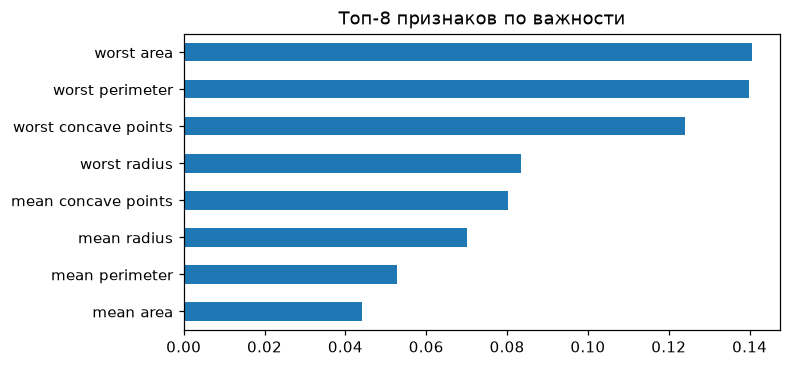

In [15]:
rf = RandomForestClassifier(n_estimators=300, max_features="sqrt", oob_score=True,
                            n_jobs=-1, random_state=RANDOM_STATE)

for name, m in [("Одно дерево", DecisionTreeClassifier(random_state=RANDOM_STATE)), ("Случайный лес", rf)]:
    s = cross_val_score(m, Xb, yb, cv=5)
    print(f"{name:15s} accuracy (5 фолдов) = {s.mean():.3f} ± {s.std():.3f}")

rf.fit(Xb_train, yb_train)
print(f"\nOOB accuracy: {rf.oob_score_:.3f} | accuracy на тесте: {rf.score(Xb_test, yb_test):.3f}")

pd.Series(rf.feature_importances_, index=bc.feature_names).sort_values().tail(8).plot.barh(figsize=(7, 3.5))
plt.title("Топ-8 признаков по важности")
plt.show()

## 6. Бустинг, LightGBM, CatBoost

Ансамбли бывают двух основных типов:

| | Бэггинг (случайный лес) | Бустинг |
|---|---|---|
| Как обучаются деревья | независимо, параллельно | последовательно: каждое исправляет ошибки предыдущих |
| Что уменьшают | разброс (variance) | смещение (bias) |
| Можно переобучиться, добавляя деревья | нет | да, поэтому нужна ранняя остановка |

Идея градиентного бустинга для регрессии: начинаем со среднего значения, считаем остатки (`y - текущее предсказание`), обучаем небольшое дерево предсказывать **остатки**, прибавляем его предсказание с маленьким весом `learning_rate`, повторяем.

### Задание 5. Бустинг руками

Допишите два места в цикле: остатки и обновление предсказания. Цель: MSE на обучающих данных после 50 деревьев меньше 0.03. Данные те же, что в части 4 (шумный синус).

In [16]:
learning_rate = 0.3
pred = np.full(len(y_reg), y_reg.mean())          # стартовое предсказание: среднее

for _ in range(50):
    residuals =  y_reg - pred                          # что мы ещё не объяснили
    t = DecisionTreeRegressor(max_depth=2).fit(X_reg, residuals)
    pred +=  learning_rate * t.predict(X_reg)             # прибавить предсказание дерева с весом learning_rate


def _check():
    mse = ((y_reg - pred) ** 2).mean()
    check(mse < 0.03, f"MSE = {mse:.4f}", f"MSE = {mse:.4f}, нужно меньше 0.03; проверьте остатки и обновление")

run_check(_check)

Верно: MSE = 0.0202


Если продолжать до сотен деревьев, модель начнёт подгонять шум. Поэтому у бустинга всегда есть `learning_rate` и **ранняя остановка**: обучение прекращается, когда качество на валидации перестаёт улучшаться.

**LightGBM** (Microsoft)

- Перед обучением значения признаков раскладываются по гистограмме (по умолчанию до 255 корзин), и пороги перебираются по корзинам, а не по всем уникальным значениям. Это сильно ускоряет обучение.
- Дерево растёт **по листьям** (leaf-wise): на каждом шаге делится тот лист, который сильнее всего уменьшает ошибку. Обычные деревья растут по уровням. Деревья получаются несимметричными и точнее при том же числе листьев, но легче переобучаются, поэтому важен `num_leaves`.

**CatBoost** (Яндекс)

- Деревья **симметричные**: на каждом уровне задаётся один и тот же вопрос для всех узлов уровня. Такое дерево быстро считается и меньше переобучается.
- Ordered boosting: остаток каждого объекта считается моделью, которая этот объект не видела (на небольших датасетах включается по умолчанию). Это уменьшает утечку информации о таргете.
- **Категориальные признаки** (город, профессия и т. п.) можно передавать как строки через `cat_features=[...]`, без one-hot кодирования.

Основные аргументы:

| Аргумент | Что делает |
|---|---|
| `n_estimators` / `iterations` | максимум деревьев; при ранней остановке ставят с запасом (1000) |
| `learning_rate` | вес каждого дерева; меньше значение — нужно больше деревьев, но точнее |
| `num_leaves` (LightGBM) / `depth` (CatBoost) | сложность одного дерева |
| `eval_set` + early stopping | валидационные данные и число раундов без улучшения, после которых обучение останавливается |

In [17]:
import lightgbm as lgb
from catboost import CatBoostClassifier

# Из обучающих данных отделяем валидацию для ранней остановки (тест не трогаем)
Xb_fit, Xb_val, yb_fit, yb_val = train_test_split(
    Xb_train, yb_train, test_size=0.2, stratify=yb_train, random_state=RANDOM_STATE)

lgbm = lgb.LGBMClassifier(n_estimators=1000, learning_rate=0.05, num_leaves=15,
                          random_state=RANDOM_STATE, verbose=-1)
lgbm.fit(Xb_fit, yb_fit, eval_set=[(Xb_val, yb_val)],
         callbacks=[lgb.early_stopping(stopping_rounds=30, verbose=False)])

cat = CatBoostClassifier(iterations=1000, learning_rate=0.05, depth=4,
                         early_stopping_rounds=30, random_seed=RANDOM_STATE, verbose=0)
cat.fit(Xb_fit, yb_fit, eval_set=(Xb_val, yb_val))

print(f"LightGBM остановился на дереве {lgbm.best_iteration_}, CatBoost на {cat.get_best_iteration()}\n")
for name, m in [("Одно дерево", single_tree), ("Случайный лес", rf), ("LightGBM", lgbm), ("CatBoost", cat)]:
    proba = m.predict_proba(Xb_test)[:, 1]
    print(f"{name:14s} accuracy = {m.score(Xb_test, yb_test):.3f}   ROC-AUC = {roc_auc_score(yb_test, proba):.3f}")

LightGBM остановился на дереве 111, CatBoost на 224

Одно дерево    accuracy = 0.918   ROC-AUC = 0.913
Случайный лес  accuracy = 0.942   ROC-AUC = 0.992
LightGBM       accuracy = 0.947   ROC-AUC = 0.993
CatBoost       accuracy = 0.959   ROC-AUC = 0.995


На таком маленьком и простом датасете разница между лесом и бустингом в пределах шума (тест — 171 объект, один объект это 0.6%). Бустинг раскрывается на больших табличных данных, где нужно выжать последние проценты.

Коротко, что брать: одно неглубокое дерево, если нужно объяснить решение человеку; случайный лес как быстрый надёжный базовый вариант; LightGBM или CatBoost, если нужна максимальная точность на таблице; CatBoost, если много категориальных признаков.